# Notebook 7: Does the oracle beat the raw window? Does JEPA add anything?

## Tests in this notebook
All hedgers use the **same** network, loss (CVaR with learnable threshold), premium, two instruments, training budget and test paths. They differ only in what extra information enters the state next to $[\log S_t/S_0,\ \tau_t]$.

| Condition | Extra input | What it tells us |
|---|---|---|
| `novol` | nothing | floor: price and time only |
| `raw_window` | last 10 raw log returns | **the policy that sees the same history JEPA sees, with no JEPA and no true variance** |
| `rv` | annualised realised variance of last 10 returns | classical statistic (the earlier baseline had a units bug; fixed here) |
| `ewma` | RiskMetrics EWMA variance ($\lambda=0.94$) | classical statistic with memory |
| `iv` | implied variance of the hedged call (Heston price inverted through Black-Scholes) | market-observable volatility proxy. Information-rich: it is a function of the true $V_t$ and the price of the option being hedged |
| `jepa_v` | JEPA variance estimate $\hat V_t$ (scalar, via linear probe) | what Notebook 6 tested |
| `jepa_z` | the 64-d JEPA embedding itself | removes the "compress to one number" bottleneck |
| `noisy_oracle` | true $V_t$ plus noise at JEPA's error level | tests whether estimation precision alone explains JEPA's result |
| `oracle` | true $V_t$ | upper bound on variance information |

## Decision tests (all with 95% paired bootstrap intervals over test paths)
- **T1** Oracle beats `raw_window` by at least 20% CVaR.
- **T1b** Oracle beats `novol` by at least 20% CVaR.
- **T2** JEPA ($\hat V$ and $z$) beats `raw_window`: does JEPA add anything over raw returns?
- **T3** Every estimator (JEPA, RV, EWMA, IV, raw window) beats `novol`.
- **T4** JEPA vs the classical estimators (RV, EWMA).
- **T5** `noisy_oracle` vs `novol` and vs JEPA: is it a precision problem?

Improvement is defined as (CVaR of B minus CVaR of A) divided by CVaR of B, so positive means A is better. Verdict rule for the 20% tests: PASS if the interval's lower bound is at least 20%, FAIL if its upper bound is below 20%, otherwise INCONCLUSIVE.

## Additions beyond what was asked (why each is here)
1. **Fresh hedger-training paths** (new simulator seed). In Notebook 6 the hedger trained on the same paths JEPA was trained on, so $\hat V$ was slightly more accurate in training than at test and the hedger may have over-trusted it.
2. **Several seeds and bootstrap intervals** so a verdict is not a coin flip. Use `PROFILE = 'full'` for 3 seeds.
3. **Part A controls**: probe on an *untrained* random encoder, a ridge probe on the raw squared-return window, annualised RV and EWMA, per-timestep accuracy of each estimator, and an embedding-collapse check (PCA earlier showed PC1 holding 99.8% of variance).
4. **Burn-in handled the same way for every scalar estimator**: for the first 10 steps (no full window) they use the model prior $E[V_t|v_0]$.

## Not covered
Transaction costs, other Heston parameter sets or strikes, and the `withL` state variant (set `INCLUDE_WITHL = True` to add it).

In [1]:
import sys, os, time, json
sys.path.insert(0, '..')
REPO_ROOT = os.path.join('..', 'deep-hedging-heston')
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import numpy as np
import torch, torch.nn as nn
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm

from heston_sim.generate import load_split
from jepa.model import HestonJEPA
from deep_hedging_heston.parameters import HestonParameters
from deep_hedging_heston.pricers import heston_call_deltas, model_deltas_on_paths
from deep_hedging_heston.simulate import MarketPaths, simulate_market

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
RESULTS = '../results'
RUNS = os.path.join(RESULTS, 'diag_runs')
os.makedirs(RUNS, exist_ok=True)
print('Device:', DEVICE)

C:\Users\USER\AppData\Roaming\Python\Python310\site-packages\google\api_core\_python_version_support.py:223: FutureWarning: You are using a non-supported Python version (3.10.20). Google will not post any further updates to google.api_core supporting this Python version. Please upgrade to the latest Python version, or at least Python 3.11, and then update google.api_core.
  warnings.warn(message, FutureWarning)


Device: cuda


In [2]:
# ---------------- configuration ----------------
PROFILE = 'quick'            # 'quick': 3000 steps, 1 seed (a first look)   |   'full': 15000 steps, 3 seeds
if PROFILE == 'quick':
    N_STEPS, SEEDS = 3000, [0]
else:
    N_STEPS, SEEDS = 15_000, [0, 1, 2]

ALPHA = 0.5                  # CVaR level
BATCH, LR = 1024, 1e-3
N_UNITS, N_LAYERS = 56, 2
W = 10                       # window length = JEPA context length
HT_PATHS, HT_SEED = 50_000, 77     # fresh hedger-training paths (JEPA/probe never saw them)
PROBE_PATHS = 30_000         # train paths used to fit the probe
EWMA_LAMBDA = 0.94
USE_IV = True                # set False to skip implied-vol (slow: calls the COS pricer 30 times per split)
INCLUDE_WITHL = False        # also run the variant with the variance-swap level in the state
BOOT = 200                   # bootstrap resamples
BUEHLER_STD, BUEHLER_CVAR = 0.3808, 0.2433
print(f'PROFILE={PROFILE}  N_STEPS={N_STEPS}  SEEDS={SEEDS}')

PROFILE=quick  N_STEPS=3000  SEEDS=[0]


## 1. Helpers (pure numpy, no torch)

In [3]:
from scipy.special import ndtr
from numpy.lib.stride_tricks import sliding_window_view

def prior_variance(t):
    # E[V_t | V_0 = v0] under Heston: used when a window estimator has no full window yet
    return hp.theta + (hp.v0 - hp.theta) * np.exp(-hp.kappa * hp.dt * t)

def est_rv(log_returns, w):
    # annualised realised variance over the last w returns (dividing by dt fixes the earlier units bug)
    N, T_ = log_returns.shape
    cs = np.concatenate([np.zeros((N, 1)), np.cumsum(log_returns.astype(np.float64) ** 2, axis=1)], axis=1)
    out = np.empty((N, T_ + 1), dtype=np.float32)
    for t in range(T_ + 1):
        out[:, t] = (cs[:, t] - cs[:, t - w]) / (w * hp.dt) if t >= w else prior_variance(t)
    return out

def est_ewma(log_returns, lam):
    # RiskMetrics EWMA of annualised squared returns, started at the known v0
    N, T_ = log_returns.shape
    out = np.empty((N, T_ + 1), dtype=np.float32)
    out[:, 0] = hp.v0
    for t in range(1, T_ + 1):
        out[:, t] = lam * out[:, t - 1] + (1 - lam) * (log_returns[:, t - 1].astype(np.float64) ** 2) / hp.dt
    return out

def window_features(log_returns, w, scale):
    # (N, T+1, w): row t holds returns r[t-w .. t-1] (oldest first), zero-padded before time 0
    N, T_ = log_returns.shape
    rp = np.concatenate([np.zeros((N, w), dtype=np.float32), log_returns.astype(np.float32)], axis=1)
    return (sliding_window_view(rp, w, axis=1) / scale).astype(np.float32)

def bs_call(S, K, sig, tau):
    sq = sig * np.sqrt(tau)
    d1 = (np.log(S / K) + 0.5 * sig ** 2 * tau) / sq
    return S * ndtr(d1) - K * ndtr(d1 - sq)

def implied_vol(price, S, K, tau, iters=60):
    # vectorised bisection on sigma in [1e-4, 3]; r = 0
    S = np.asarray(S, dtype=np.float64)
    intrinsic = np.maximum(S - K, 0.0)
    price = np.clip(np.asarray(price, dtype=np.float64), intrinsic + 1e-10, S - 1e-10)
    lo = np.full_like(price, 1e-4); hi = np.full_like(price, 3.0)
    for _ in range(iters):
        mid = 0.5 * (lo + hi)
        too_high = bs_call(S, K, mid, tau) > price
        hi = np.where(too_high, mid, hi); lo = np.where(too_high, lo, mid)
    return 0.5 * (lo + hi)

def corr2(a, b):
    if np.std(a) < 1e-12 or np.std(b) < 1e-12:
        return 0.0
    return float(np.corrcoef(a, b)[0, 1] ** 2)

def cvar_np(Wt, alpha=None):
    alpha = ALPHA if alpha is None else alpha
    L = -np.asarray(Wt); k = int(alpha * len(L))
    return float(np.partition(L, k)[k:].mean())

def boot_improvement(Wa, Wb, B=200, seed=0):
    # Wa, Wb: lists (one array per training seed) of terminal wealth on the SAME test paths.
    # improvement = (CVaR_b - CVaR_a) / CVaR_b ; positive means A is better.
    n = len(Wa[0]); rng = np.random.default_rng(seed)
    ca = np.mean([cvar_np(w) for w in Wa]); cb = np.mean([cvar_np(w) for w in Wb])
    pt = (cb - ca) / cb
    samples = []
    for _ in range(B):
        idx = rng.integers(0, n, n)
        a = np.mean([cvar_np(w[idx]) for w in Wa]); b = np.mean([cvar_np(w[idx]) for w in Wb])
        samples.append((b - a) / b)
    lo, hi = np.percentile(samples, [2.5, 97.5])
    return float(pt), float(lo), float(hi)

def verdict(lo, hi, thr):
    if thr > 0:
        return 'PASS' if lo >= thr else ('FAIL' if hi < thr else 'INCONCLUSIVE')
    return 'A BETTER' if lo > 0 else ('A WORSE' if hi < 0 else 'NO CLEAR DIFFERENCE')

def features(cond, d, include_L):
    # state = [log S/S0, (extra info), (VarSwap level), tau]; skip=True columns are pre-scaled already
    N = d['stocks'].shape[0]
    tau = np.broadcast_to((hp.T - hp.dt * np.arange(T)).astype(np.float32), (N, T))[:, :, None]
    blocks = [(np.log(d['stocks'][:, :T] / hp.S0)[:, :, None], False)]
    if cond == 'oracle':
        blocks.append((d['variance'][:, :T, None], False))
    elif cond == 'raw_window':
        blocks.append((d['win'][:, :T, :], True))
    elif cond == 'jepa_z':
        blocks.append((d['z'][:, :T, :], True))
    elif cond != 'novol':
        blocks.append((d['est'][cond][:, :T, None], False))
    if include_L:
        blocks.append((d['variance_swap'][:, :T, None], False))
    blocks.append((tau, False))
    F = np.concatenate([b for b, _ in blocks], axis=-1).astype(np.float32)
    skip = np.concatenate([np.full(b.shape[-1], s) for b, s in blocks])
    return F, skip
print('helpers defined')

helpers defined


## 2. Data, JEPA, probe, estimators

In [4]:
hp = HestonParameters()
T = hp.timesteps
print(f'Heston params: v0={hp.v0} theta={hp.theta} kappa={hp.kappa} xi={hp.xi} rho={hp.rho} S0={hp.S0} K={hp.K} T={hp.T:.4f} steps={T}')

train_data = load_split('train', '../data')
test_data = load_split('test', '../data')

def make_set(stocks, variance, vswap, payoff):
    lr = np.diff(np.log(stocks.astype(np.float64)), axis=1).astype(np.float32)
    return dict(stocks=stocks.astype(np.float32), variance=variance.astype(np.float32),
                variance_swap=vswap.astype(np.float32), payoff=payoff.astype(np.float32), log_returns=lr)

fresh = simulate_market(hp, seed=HT_SEED, nr_of_simulated_paths=HT_PATHS)
HT = make_set(fresh.Stocks, fresh.Variance, fresh.Variance_swap, fresh.Payoff)     # hedger training paths
TE = make_set(test_data['stocks'], test_data['variance'], test_data['variance_swap'], test_data['payoff'])
R_SD = float(train_data['log_returns'].std())

ckpt = torch.load('../checkpoints/jepa_prices.pt', map_location=DEVICE, weights_only=False)
cfg = ckpt['config']
assert cfg['context_len'] == W, 'W must equal the JEPA context length'
D = cfg['d_model']
def new_jepa():
    return HestonJEPA(feature_dim=cfg['feature_dim'], d_model=D, n_heads=cfg['n_heads'], n_layers=cfg['n_layers'],
                      ema_momentum=cfg['ema_momentum'], var_reg_coeff=cfg['var_reg_coeff']).to(DEVICE)
jepa = new_jepa(); jepa.load_state_dict(ckpt['model_state']); jepa.eval()

def encode_all(model, log_returns, bs=4096):
    # embedding of the window ending at each time t >= W (zeros before that)
    N, T_ = log_returns.shape
    Z = np.zeros((N, T_ + 1, D), dtype=np.float32)
    for t in tqdm(range(W, T_ + 1), desc='encoding', leave=False):
        ctx = log_returns[:, t - W:t][:, :, None]
        for s in range(0, N, bs):
            x = torch.tensor(ctx[s:s + bs], dtype=torch.float32).to(DEVICE)
            Z[s:s + bs, t] = model.encode(x).cpu().numpy()
    return Z

def get_z(name, log_returns):
    p = os.path.join(RESULTS, f'z_{name}.npy')
    if os.path.exists(p):
        Z = np.load(p)
        if Z.shape[0] == log_returns.shape[0]:
            print('loaded cached', name); return Z
    Z = encode_all(jepa, log_returns); np.save(p, Z); return Z

psub = np.random.default_rng(42).choice(train_data['log_returns'].shape[0], PROBE_PATHS, replace=False)
PTR = dict(log_returns=train_data['log_returns'][psub], variance=train_data['variance'][psub])
Z_ptr = get_z(f'probe_train_n{PROBE_PATHS}', PTR['log_returns'])
Z_ht = get_z(f'ht_s{HT_SEED}_n{HT_PATHS}', HT['log_returns'])
Z_te = get_z('te', TE['log_returns'])

# linear probe on the frozen embedding, pooled over t >= W
Ztr = Z_ptr[:, W:, :].reshape(-1, D); Vtr = PTR['variance'][:, W:].reshape(-1)
zs = StandardScaler().fit(Ztr)
ridge = Ridge(alpha=1.0).fit(zs.transform(Ztr), Vtr)
print('probe fitted on', Ztr.shape[0], 'samples')

Heston params: v0=0.04 theta=0.04 kappa=1.0 xi=2.0 rho=-0.7 S0=100 K=100 T=0.0822 steps=30


c:\Users\USER\OneDrive\Desktop\IIT\Thesis\Implementation\Git Repo\JEPA---Deep-Hedging\Vibe coded experiment 2\Jepa-Heston\notebooks\..\jepa\encoder.py:94: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


encoding:   0%|          | 0/21 [00:00<?, ?it/s]

encoding:   0%|          | 0/21 [00:00<?, ?it/s]

encoding:   0%|          | 0/21 [00:00<?, ?it/s]

probe fitted on 630000 samples


In [5]:
def get_iv(name, d):
    p = os.path.join(RESULTS, f'iv_{name}.npy')
    if os.path.exists(p):
        a = np.load(p)
        if a.shape[0] == d['stocks'].shape[0]:
            print('loaded cached IV', name); return a
    N = d['stocks'].shape[0]; out = np.empty((N, T + 1), dtype=np.float32)
    for t in tqdm(range(T), desc=f'implied vol {name}', leave=False):
        tau = hp.T - hp.dt * t
        price, _, _ = heston_call_deltas(d['stocks'][:, t], d['variance'][:, t], tau, hp)
        out[:, t] = implied_vol(price, d['stocks'][:, t], hp.K, tau) ** 2      # implied VARIANCE
    out[:, T] = out[:, T - 1]
    np.save(p, out); return out

def attach(d, Z, name):
    N = Z.shape[0]
    Vhat = np.empty((N, T + 1), dtype=np.float32)
    Vhat[:, W:] = np.clip(ridge.predict(zs.transform(Z[:, W:, :].reshape(-1, D))).reshape(N, -1), 0, None)
    Vhat[:, :W] = prior_variance(np.arange(W))[None, :]
    Zs = ((Z - zs.mean_) / zs.scale_).astype(np.float32); Zs[:, :W, :] = 0.0
    d['z'] = Zs
    d['win'] = window_features(d['log_returns'], W, R_SD)
    d['est'] = {'rv': est_rv(d['log_returns'], W), 'ewma': est_ewma(d['log_returns'], EWMA_LAMBDA), 'jepa_v': Vhat}
    if USE_IV:
        d['est']['iv'] = get_iv(name, d)

attach(HT, Z_ht, f'ht_s{HT_SEED}_n{HT_PATHS}')
attach(TE, Z_te, 'te')

# noisy oracle: true V plus noise at the size of JEPA's error on the hedger-training paths
NOISE_SD = float(np.std((HT['est']['jepa_v'] - HT['variance'])[:, W:]))
rng = np.random.default_rng(123)
for d in (HT, TE):
    noisy = np.clip(d['variance'] + NOISE_SD * rng.standard_normal(d['variance'].shape), 0, None).astype(np.float32)
    noisy[:, :W] = prior_variance(np.arange(W))[None, :]
    d['est']['noisy_oracle'] = noisy
print(f'JEPA residual sd (noise level for noisy_oracle): {NOISE_SD:.5f}   (mean V = {HT["variance"].mean():.5f})')

implied vol ht_s77_n50000:   0%|          | 0/30 [00:00<?, ?it/s]

implied vol te:   0%|          | 0/30 [00:00<?, ?it/s]

JEPA residual sd (noise level for noisy_oracle): 0.04354   (mean V = 0.03933)


## 3. Part A diagnostics: what does JEPA actually give us?
These are the controls that were missing from the first report.

mean squared correlation with true V_t, t >= W (calibration-free):
  rv       0.666
  ewma     0.677
  iv       0.908
  jepa_v   0.756


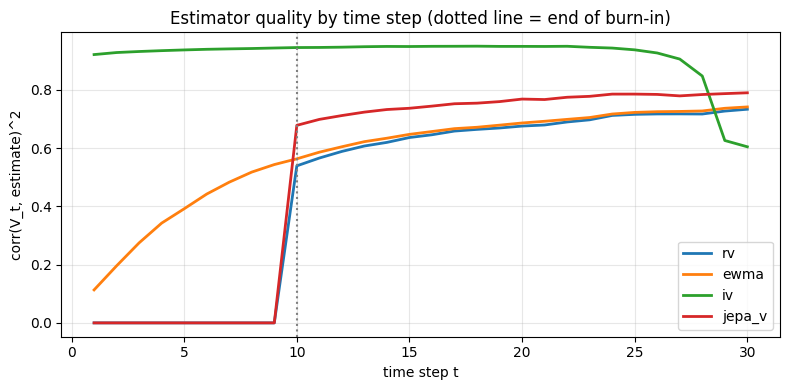

In [6]:
# ---- D1: per-timestep quality of each scalar estimator (squared correlation with true V, test paths) ----
EST_NAMES = [n for n in ['rv', 'ewma', 'iv', 'jepa_v'] if n in TE['est']]
r2t = {n: [corr2(TE['variance'][:, t], TE['est'][n][:, t]) for t in range(1, T + 1)] for n in EST_NAMES}
print('mean squared correlation with true V_t, t >= W (calibration-free):')
for n in EST_NAMES:
    print(f'  {n:8s} {np.mean(r2t[n][W - 1:]):.3f}')

fig, ax = plt.subplots(figsize=(8, 4))
for n in EST_NAMES:
    ax.plot(range(1, T + 1), r2t[n], label=n, lw=2)
ax.axvline(W, color='gray', ls=':'); ax.set_xlabel('time step t'); ax.set_ylabel('corr(V_t, estimate)^2')
ax.set_title('Estimator quality by time step (dotted line = end of burn-in)'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(os.path.join(RESULTS, 'diag_estimator_by_t.png'), dpi=150); plt.show()

In [7]:
# ---- D2: probe-level comparison (R^2 on test windows, t >= W). Controls for the JEPA claim. ----
NP = 20_000
def pooled(arr, V):
    return arr[:NP, W:, :].reshape(-1, arr.shape[-1]), V[:NP, W:].reshape(-1)

def fit_eval(Xtr, ytr, Xte, yte):
    sc = StandardScaler().fit(Xtr)
    m = Ridge(alpha=1.0).fit(sc.transform(Xtr), ytr)
    return r2_score(yte, m.predict(sc.transform(Xte)))

Vte_p = TE['variance'][:NP, W:].reshape(-1)
rows = {}
Xa, ya = pooled(Z_ptr, PTR['variance']); Xb, yb = pooled(Z_te, TE['variance'])
rows['JEPA embedding, linear probe'] = fit_eval(Xa, ya, Xb, yb)

torch.manual_seed(0)
rand_model = new_jepa(); rand_model.eval()                         # UNTRAINED encoder, same architecture
Zr_tr = encode_all(rand_model, PTR['log_returns'][:NP]); Zr_te = encode_all(rand_model, TE['log_returns'][:NP])
Xa, ya = pooled(Zr_tr, PTR['variance']); Xb, yb = pooled(Zr_te, TE['variance'])
rows['RANDOM (untrained) encoder, linear probe'] = fit_eval(Xa, ya, Xb, yb)

Wtr = window_features(PTR['log_returns'][:NP], W, 1.0); Wte = window_features(TE['log_returns'][:NP], W, 1.0)
for nm, f in [('Ridge on squared returns (window)', lambda a: a ** 2), ('Ridge on |returns| (window)', np.abs),
              ('Ridge on raw returns (window)', lambda a: a)]:
    Xa, ya = pooled(f(Wtr), PTR['variance']); Xb, yb = pooled(f(Wte), TE['variance'])
    rows[nm] = fit_eval(Xa, ya, Xb, yb)

rv_p = TE['est']['rv'][:NP, W:].reshape(-1); ew_p = TE['est']['ewma'][:NP, W:].reshape(-1)
rows['Annualised RV (no fitting), raw R2'] = r2_score(Vte_p, rv_p)
rows['Annualised RV, squared correlation'] = corr2(Vte_p, rv_p)
rows['EWMA (no fitting), raw R2'] = r2_score(Vte_p, ew_p)
rows['Predict the mean'] = 0.0

print('\nTest R2 for recovering V_t from returns:')
for k, v in rows.items():
    print(f'  {k:46s} {v:7.3f}')
print('\nReference from earlier: supervised LSTM 0.800, JEPA linear probe 0.754 (different subsample).')

c:\Users\USER\OneDrive\Desktop\IIT\Thesis\Implementation\Git Repo\JEPA---Deep-Hedging\Vibe coded experiment 2\Jepa-Heston\notebooks\..\jepa\encoder.py:94: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


encoding:   0%|          | 0/21 [00:00<?, ?it/s]

encoding:   0%|          | 0/21 [00:00<?, ?it/s]


Test R2 for recovering V_t from returns:
  JEPA embedding, linear probe                     0.756
  RANDOM (untrained) encoder, linear probe         0.788
  Ridge on squared returns (window)                0.691
  Ridge on |returns| (window)                      0.688
  Ridge on raw returns (window)                    0.263
  Annualised RV (no fitting), raw R2               0.660
  Annualised RV, squared correlation               0.676
  EWMA (no fitting), raw R2                        0.610
  Predict the mean                                 0.000

Reference from earlier: supervised LSTM 0.800, JEPA linear probe 0.754 (different subsample).


In [8]:
# ---- D3: embedding collapse check ----
def collapse_stats(Z):
    X = Z[:NP, W:, :].reshape(-1, Z.shape[-1]).astype(np.float64)
    sd = X.std(0)
    ev = np.clip(np.linalg.eigvalsh(np.cov(X.T)), 0, None)
    Xs = (X - X.mean(0)) / (sd + 1e-12)
    evs = np.clip(np.linalg.eigvalsh(np.cov(Xs.T)), 0, None)
    return dict(sd_min=sd.min(), sd_median=float(np.median(sd)), sd_max=sd.max(),
                top1_share=float(ev.max() / ev.sum()), effective_rank=float(ev.sum() ** 2 / (ev ** 2).sum()),
                effective_rank_standardised=float(evs.sum() ** 2 / (evs ** 2).sum()))
for nm, Z in [('trained JEPA', Z_te), ('random encoder', Zr_te)]:
    s = collapse_stats(Z)
    print(f'{nm:15s} ' + '  '.join(f'{k}={v:.4g}' for k, v in s.items()))
print(f'(out of {D} dimensions; effective rank near 1 means the embedding is nearly one-dimensional)')

trained JEPA    sd_min=0.0001331  sd_median=0.0007696  sd_max=0.002269  top1_share=0.9476  effective_rank=1.113  effective_rank_standardised=1.607
random encoder  sd_min=0.0001541  sd_median=0.00152  sd_max=0.00493  top1_share=0.9732  effective_rank=1.055  effective_rank_standardised=1.539
(out of 64 dimensions; effective rank near 1 means the embedding is nearly one-dimensional)


## 4. Hedging benchmarks (test set)
Check these against the previous notebook before training: analytical std about 0.37, CVaR about 0.24, premium 1.69.

In [9]:
price0, _, _ = heston_call_deltas(np.array([hp.S0]), np.array([hp.v0]), hp.T, hp)
PREMIUM = float(price0[0])
dS_te_np = (TE['stocks'][:, 1:] - TE['stocks'][:, :-1]).astype(np.float64)
dL_te_np = (TE['variance_swap'][:, 1:] - TE['variance_swap'][:, :-1]).astype(np.float64)
dS_ht_np = (HT['stocks'][:, 1:] - HT['stocks'][:, :-1])
dL_ht_np = (HT['variance_swap'][:, 1:] - HT['variance_swap'][:, :-1])

W_unhedged = PREMIUM - TE['payoff']
mkt = MarketPaths(Stocks=TE['stocks'], Variance=TE['variance'], Variance_swap=TE['variance_swap'], Payoff=TE['payoff'])
d1_an, d2_an = model_deltas_on_paths(mkt, hp)
W_analytical = PREMIUM + (d1_an * dS_te_np + d2_an * dL_te_np).sum(1) - TE['payoff']
D2_SCALE = float(dS_ht_np.std() / dL_ht_np.std())
print(f'premium {PREMIUM:.4f}   D2_SCALE {D2_SCALE:.1f}')
for nm, Wt in [('unhedged', W_unhedged), ('analytical', W_analytical)]:
    print(f'{nm:11s} mean={Wt.mean():+.4f} std={Wt.std():.4f} CVaR={cvar_np(Wt):.4f}')
print(f'Buehler ref  std={BUEHLER_STD} CVaR={BUEHLER_CVAR}')

premium 1.6918   D2_SCALE 1026.8
unhedged    mean=+0.0005 std=2.1635 CVaR=1.4718
analytical  mean=-0.0021 std=0.3739 CVaR=0.2412
Buehler ref  std=0.3808 CVaR=0.2433


## 5. Hedger (identical to Notebook 6, which passed the synthetic smoke test)

In [10]:
class Hedger(nn.Module):
    def __init__(self, in_dim, d2_scale, n_units=N_UNITS, n_layers=N_LAYERS):
        super().__init__()
        layers = [nn.Linear(in_dim + 2, n_units), nn.Tanh()]
        for _ in range(n_layers - 1):
            layers += [nn.Linear(n_units, n_units), nn.Tanh()]
        layers += [nn.Linear(n_units, 2)]
        self.net = nn.Sequential(*layers)
        self.d2_scale = d2_scale
        self.w = nn.Parameter(torch.zeros(()))

    def forward(self, x, prev_raw):
        raw = self.net(torch.cat([x, prev_raw], dim=-1))
        return raw, torch.stack([raw[:, 0], raw[:, 1] * self.d2_scale], dim=-1)

def terminal_wealth(net, X, dS, dL, payoff):
    N, T_, _ = X.shape
    prev = torch.zeros(N, 2, device=X.device); pnl = torch.zeros(N, device=X.device)
    for t in range(T_):
        raw, d = net(X[:, t, :], prev)
        pnl = pnl + d[:, 0] * dS[:, t] + d[:, 1] * dL[:, t]
        prev = raw
    return PREMIUM + pnl - payoff

def cvar_loss(Wt, w, alpha):
    return w + torch.relu(-Wt - w).mean() / (1.0 - alpha)

def train_one(X, dS, dL, payoff, label, seed):
    torch.manual_seed(seed)
    net = Hedger(X.shape[-1], D2_SCALE).to(DEVICE)
    opt = torch.optim.Adam([{'params': net.net.parameters(), 'lr': LR}, {'params': [net.w], 'lr': 1e-2}])
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=N_STEPS)
    g = torch.Generator().manual_seed(seed); n = X.shape[0]; hist, run = [], []
    pbar = tqdm(range(N_STEPS), desc=label)
    for step in pbar:
        idx = torch.randint(0, n, (BATCH,), generator=g).to(DEVICE)
        Wt = terminal_wealth(net, X[idx], dS[idx], dL[idx], payoff[idx])
        loss = cvar_loss(Wt, net.w, ALPHA)
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(net.parameters(), 1.0); opt.step(); sch.step()
        run.append(loss.item())
        if (step + 1) % 200 == 0:
            hist.append(float(np.mean(run))); run = []; pbar.set_postfix({'CVaR': f'{hist[-1]:.4f}'})
    return net, np.array(hist)

def eval_W(net, X, dS, dL, payoff, bs=25_000):
    net.eval(); out = []
    with torch.no_grad():
        for s in range(0, X.shape[0], bs):
            out.append(terminal_wealth(net, X[s:s+bs], dS[s:s+bs], dL[s:s+bs], payoff[s:s+bs]).cpu().numpy())
    return np.concatenate(out)
print('defined')

defined


## 6. Run all conditions
Each finished model is saved in `results/diag_runs/` (the file name includes the step count). If you stop the notebook, run this cell again and it **skips finished models**. Time one condition first: the full profile trains 8 or 9 conditions times 3 seeds.

In [11]:
VARIANTS = {'clean': False}
if INCLUDE_WITHL:
    VARIANTS['withL'] = True
CONDITIONS = ['oracle', 'novol', 'raw_window', 'rv', 'ewma', 'jepa_v', 'jepa_z', 'noisy_oracle'] + (['iv'] if USE_IV else [])

def to_t(a): return torch.tensor(np.ascontiguousarray(a), dtype=torch.float32, device=DEVICE)
dS_ht, dL_ht, pay_ht = to_t(dS_ht_np), to_t(dL_ht_np), to_t(HT['payoff'])
dS_te, dL_te, pay_te = to_t(dS_te_np), to_t(dL_te_np), to_t(TE['payoff'])

for vname, incL in VARIANTS.items():
    for cond in CONDITIONS:
        todo = [s for s in SEEDS if not os.path.exists(os.path.join(RUNS, f'{vname}_{cond}_s{s}_n{N_STEPS}_W.npy'))]
        if not todo:
            print('skip (done):', vname, cond); continue
        Fh, skip = features(cond, HT, incL); Ft, _ = features(cond, TE, incL)
        flat = Fh.reshape(-1, Fh.shape[-1]); mu, sd = flat.mean(0), flat.std(0) + 1e-8
        mu[skip] = 0.0; sd[skip] = 1.0
        Xh, Xt = to_t((Fh - mu) / sd), to_t((Ft - mu) / sd)
        del Fh, Ft, flat
        for seed in todo:
            key = f'{vname}_{cond}_s{seed}_n{N_STEPS}'
            net, hist = train_one(Xh, dS_ht, dL_ht, pay_ht, key, seed)
            Wt = eval_W(net, Xt, dS_te, dL_te, pay_te)
            np.save(os.path.join(RUNS, key + '_W.npy'), Wt); np.save(os.path.join(RUNS, key + '_hist.npy'), hist)
            print(f'{key}: mean={Wt.mean():+.4f} std={Wt.std():.4f} CVaR={cvar_np(Wt):.4f}')
        del Xh, Xt
        if DEVICE == 'cuda':
            torch.cuda.empty_cache()

clean_oracle_s0_n3000:   0%|          | 0/3000 [00:00<?, ?it/s]

clean_oracle_s0_n3000: mean=-0.0017 std=0.3937 CVaR=0.2556


clean_novol_s0_n3000:   0%|          | 0/3000 [00:00<?, ?it/s]

clean_novol_s0_n3000: mean=-0.0025 std=0.5803 CVaR=0.3612


clean_raw_window_s0_n3000:   0%|          | 0/3000 [00:00<?, ?it/s]

clean_raw_window_s0_n3000: mean=-0.0037 std=0.5881 CVaR=0.3571


... (8 outputs left out)

clean_noisy_oracle_s0_n3000:   0%|          | 0/3000 [00:00<?, ?it/s]

clean_noisy_oracle_s0_n3000: mean=-0.0022 std=0.5209 CVaR=0.3332


clean_iv_s0_n3000:   0%|          | 0/3000 [00:00<?, ?it/s]

clean_iv_s0_n3000: mean=-0.0018 std=0.3968 CVaR=0.2584


## 7. Results and decision tests

In [12]:
def get_Ws(vname, cond):
    out = []
    for s in SEEDS:
        p = os.path.join(RUNS, f'{vname}_{cond}_s{s}_n{N_STEPS}_W.npy')
        if os.path.exists(p): out.append(np.load(p))
    return out

ALL = {}
for vname in VARIANTS:
    Ws = {c: get_Ws(vname, c) for c in CONDITIONS}; Ws = {c: w for c, w in Ws.items() if w}
    ALL[vname] = Ws
    print('\n' + '=' * 76); print(f'VARIANT {vname}  (seeds per condition: {[len(w) for w in Ws.values()]})'); print('=' * 76)
    rows = {c: dict(cvar=np.mean([cvar_np(x) for x in w]), sd=np.std([cvar_np(x) for x in w]),
                    std=np.mean([x.std() for x in w])) for c, w in Ws.items()}
    print(f'{"condition":<14}{"CVaR":>9}{"seed sd":>9}{"std":>9}')
    for c, r in sorted(rows.items(), key=lambda kv: kv[1]['cvar']):
        print(f'{c:<14}{r["cvar"]:>9.4f}{r["sd"]:>9.4f}{r["std"]:>9.4f}')
    print(f'{"analytical":<14}{cvar_np(W_analytical):>9.4f}{"":>9}{W_analytical.std():>9.4f}')
    print(f'{"unhedged":<14}{cvar_np(W_unhedged):>9.4f}{"":>9}{W_unhedged.std():>9.4f}')
    print(f'{"Buehler ref":<14}{BUEHLER_CVAR:>9.4f}{"":>9}{BUEHLER_STD:>9.4f}')

    TESTS = [
        ('T1  Oracle beats raw_window by >= 20%', 'oracle', 'raw_window', 0.20),
        ('T1b Oracle beats novol by >= 20%', 'oracle', 'novol', 0.20),
        ('T2a JEPA-V vs raw_window', 'jepa_v', 'raw_window', 0.0),
        ('T2b JEPA-z vs raw_window', 'jepa_z', 'raw_window', 0.0),
        ('T3a JEPA-V vs novol', 'jepa_v', 'novol', 0.0),
        ('T3b JEPA-z vs novol', 'jepa_z', 'novol', 0.0),
        ('T3c raw_window vs novol', 'raw_window', 'novol', 0.0),
        ('T3d rv vs novol', 'rv', 'novol', 0.0),
        ('T3e ewma vs novol', 'ewma', 'novol', 0.0),
        ('T3f iv vs novol', 'iv', 'novol', 0.0),
        ('T4a JEPA-V vs rv', 'jepa_v', 'rv', 0.0),
        ('T4b JEPA-V vs ewma', 'jepa_v', 'ewma', 0.0),
        ('T4c JEPA-z vs ewma', 'jepa_z', 'ewma', 0.0),
        ('T5a noisy_oracle vs novol', 'noisy_oracle', 'novol', 0.0),
        ('T5b JEPA-V vs noisy_oracle', 'jepa_v', 'noisy_oracle', 0.0),
    ]
    print('\nImprovement = (CVaR_B - CVaR_A)/CVaR_B, 95% paired bootstrap over test paths. Positive: A better.')
    out = []
    for label, a, b, thr in TESTS:
        if a not in Ws or b not in Ws: continue
        pt, lo, hi = boot_improvement(Ws[a], Ws[b], B=BOOT)
        v = verdict(lo, hi, thr)
        print(f'{label:<42} {100*pt:+7.1f}%  [{100*lo:+6.1f}, {100*hi:+6.1f}]  {v}')
        out.append(dict(test=label, a=a, b=b, threshold=thr, point=pt, lo=lo, hi=hi, verdict=v))
    if all(c in rows for c in ('oracle', 'novol')):
        gap = rows['novol']['cvar'] - rows['oracle']['cvar']
        noise = max(rows['oracle']['sd'], rows['novol']['sd'], 0.005)
        print(f'\nOracle vs novol CVaR gap = {gap:.4f} (seed noise ~ {noise:.4f})')
        if gap > 3 * noise:
            for c in ['raw_window', 'rv', 'ewma', 'iv', 'jepa_v', 'jepa_z', 'noisy_oracle']:
                if c in rows:
                    print(f'  share of the gap recovered by {c:<13}: {100*(rows["novol"]["cvar"]-rows[c]["cvar"])/gap:6.1f}%')
        else:
            print('  gap is within noise: "share of gap recovered" is not interpretable')
    json.dump(out, open(os.path.join(RESULTS, f'diag_tests_{vname}_n{N_STEPS}.json'), 'w'), indent=1)


VARIANT clean  (seeds per condition: [1, 1, 1, 1, 1, 1, 1, 1, 1])
condition          CVaR  seed sd      std
oracle           0.2556   0.0000   0.3937
iv               0.2584   0.0000   0.3968
noisy_oracle     0.3332   0.0000   0.5209
ewma             0.3392   0.0000   0.5465
rv               0.3503   0.0000   0.5572
jepa_v           0.3504   0.0000   0.5570
raw_window       0.3571   0.0000   0.5881
novol            0.3612   0.0000   0.5803
jepa_z           0.3677   0.0000   0.5954
analytical       0.2412            0.3739
unhedged         1.4718            2.1635
Buehler ref      0.2433            0.3808

Improvement = (CVaR_B - CVaR_A)/CVaR_B, 95% paired bootstrap over test paths. Positive: A better.
T1  Oracle beats raw_window by >= 20%        +28.4%  [ +27.2,  +29.6]  PASS
T1b Oracle beats novol by >= 20%             +29.2%  [ +28.2,  +30.2]  PASS
T2a JEPA-V vs raw_window                      +1.9%  [  +0.9,   +2.7]  A BETTER
T2b JEPA-z vs raw_window                      -3.0%  [  

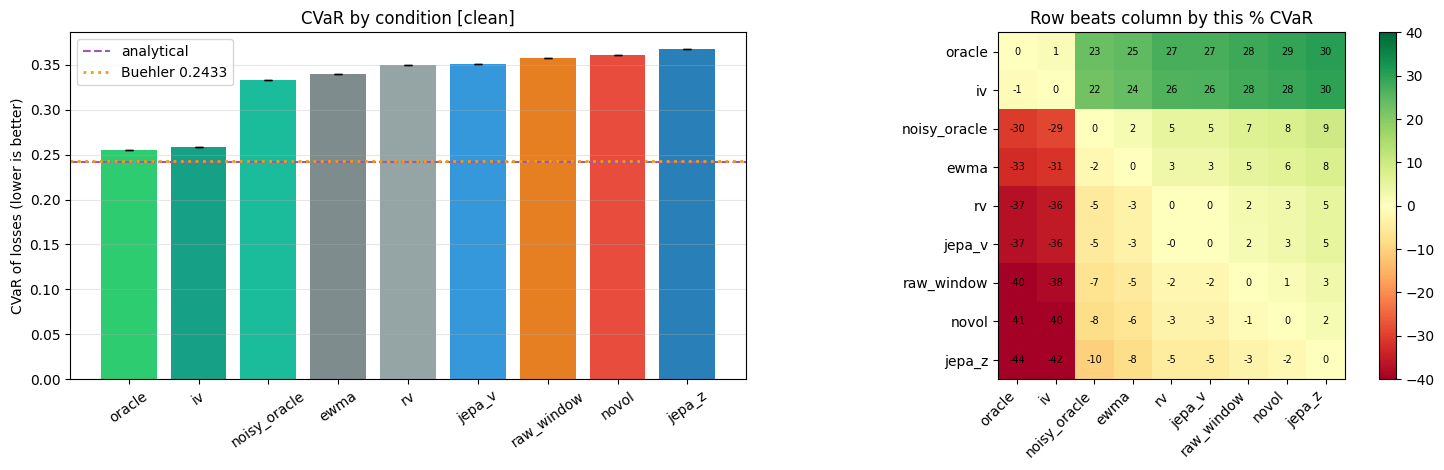

In [13]:
# ---- plots ----
colors = {'oracle': '#2ecc71', 'novol': '#e74c3c', 'raw_window': '#e67e22', 'rv': '#95a5a6', 'ewma': '#7f8c8d',
          'iv': '#16a085', 'jepa_v': '#3498db', 'jepa_z': '#2980b9', 'noisy_oracle': '#1abc9c'}
for vname, Ws in ALL.items():
    conds = sorted(Ws, key=lambda c: np.mean([cvar_np(x) for x in Ws[c]]))
    m = [np.mean([cvar_np(x) for x in Ws[c]]) for c in conds]; s = [np.std([cvar_np(x) for x in Ws[c]]) for c in conds]
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
    ax = axes[0]
    ax.bar(conds, m, yerr=s, color=[colors.get(c, '#555') for c in conds], capsize=3)
    ax.axhline(cvar_np(W_analytical), color='#9b59b6', ls='--', label='analytical')
    ax.axhline(BUEHLER_CVAR, color='#f39c12', ls=':', lw=2, label=f'Buehler {BUEHLER_CVAR}')
    ax.set_ylabel('CVaR of losses (lower is better)'); ax.set_title(f'CVaR by condition [{vname}]')
    ax.tick_params(axis='x', rotation=35); ax.legend(); ax.grid(axis='y', alpha=0.3)
    M = np.array([[100 * (m[j] - m[i]) / m[j] for j in range(len(conds))] for i in range(len(conds))])
    ax = axes[1]; im = ax.imshow(M, cmap='RdYlGn', vmin=-40, vmax=40)
    ax.set_xticks(range(len(conds))); ax.set_xticklabels(conds, rotation=45, ha='right'); ax.set_yticks(range(len(conds))); ax.set_yticklabels(conds)
    for i in range(len(conds)):
        for j in range(len(conds)):
            ax.text(j, i, f'{M[i, j]:.0f}', ha='center', va='center', fontsize=7)
    ax.set_title('Row beats column by this % CVaR'); plt.colorbar(im, ax=ax)
    plt.tight_layout(); plt.savefig(os.path.join(RESULTS, f'diag_summary_{vname}_n{N_STEPS}.png'), dpi=150); plt.show()

## How to read the outcomes
- **T1 PASS**: the oracle is at least 20% better than a hedger that sees raw returns. True variance then carries information that raw returns do not make usable, which is the headroom any inference method is aiming at.
- **T1 FAIL**: raw returns already give most of what true variance gives. Variance inference has little to add in this setup, whatever JEPA does.
- **T2 not better than raw_window**: JEPA is not adding anything the hedger could not extract from the returns itself.
- **T5a close to oracle, T5b JEPA worse**: precision alone does not explain JEPA's weakness; its errors are structured.
- **T5a close to novol**: even modestly noisy variance is not useful, so only much more precise estimates would help.
- **Probe controls (section 3)**: if the random encoder or the ridge on squared returns gets close to JEPA's R2, the Part A claim "JEPA learned volatility" needs to be softened.
- With one seed (`quick`), treat every verdict as provisional. Re-run with `PROFILE = 'full'` before quoting numbers.